In [22]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient101_frame01.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient101_frame14.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient102_frame01.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient102_frame13.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient103_frame01.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient103_frame11.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient104_frame01.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient104_frame11.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient105_frame01.h5
/kaggle/input/datasets/anhoangvo/acdc

Patient 001 to 100 have individual frame h5 files and also individual slice h5 files for each frame file, patient 101 to 150 only seem to have frame files not individual slice files

In [23]:
!pip install scikit-image

In [24]:
import random
import h5py
import matplotlib.pyplot as plt
import numpy as np
import os
import glob
import re
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from skimage.measure import marching_cubes
from scipy.ndimage import gaussian_filter, distance_transform_edt

Fixing Random Seed


In [25]:
# Seed
SEED = 42

# Python
random.seed(SEED)

# NumPy
np.random.seed(SEED)

# PyTorch CPU
torch.manual_seed(SEED)

# PyTorch GPU
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Deterministic operations
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Strict reproducibility (where supported)
torch.use_deterministic_algorithms(True,warn_only=True)

Prepare Training and Testing data

In [26]:
train_files = glob.glob(
    "/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_training_volumes/*.h5",
    recursive=True
)

print("Total H5 files:", len(train_files))
print(train_files[:10])

test_files = glob.glob(
    "/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/*.h5",
    recursive=True
)

print("Total H5 files:", len(test_files))
print(test_files[:10])

file_path = train_files[25]

with h5py.File(file_path, "r") as f:
    print("File:", file_path)
    print("Keys:", list(f.keys()))

    for key in f.keys():
        arr = f[key][:]

        print(f"\n{key}")
        print("Shape:", arr.shape)
        print("Data type:", arr.dtype)
        print("Unique values:", np.unique(arr)[:20])

Total H5 files: 200
['/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_training_volumes/patient001_frame01.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_training_volumes/patient001_frame12.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_training_volumes/patient002_frame01.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_training_volumes/patient002_frame12.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_training_volumes/patient003_frame01.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_training_volumes/patient003_frame15.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_training_volumes/patient004_frame01.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_training_volumes/patient004_frame15.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_training_volumes/pati

In [27]:
with h5py.File(train_files[0], "r") as f:
    print(f.keys())


with h5py.File(train_files[0], "r") as f:
    print(type(f['image']))
    print(type(f['image'][:]))#this is how you see array in h5py object
    

    print(type(f['label']))
    print(type(f['label'][:]))
    print(np.unique(f['label'][:]))

    print(type(f['scribble']))
    print(type(f['scribble'][:]))
    print(np.unique(f['scribble'][:]))
    temp1=f['image'][:]
    temp=f['scribble'][:]

<KeysViewHDF5 ['image', 'label', 'scribble']>
<class 'h5py._hl.dataset.Dataset'>
<class 'numpy.ndarray'>
<class 'h5py._hl.dataset.Dataset'>
<class 'numpy.ndarray'>
[0 1 2 3]
<class 'h5py._hl.dataset.Dataset'>
<class 'numpy.ndarray'>
[0 1 2 3 4]


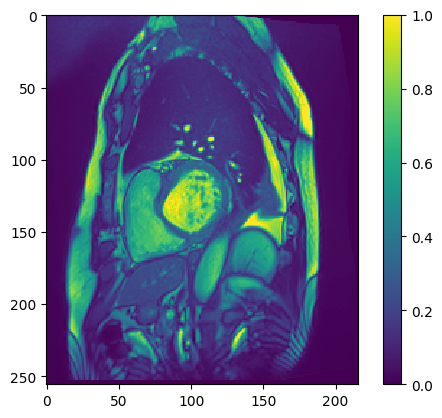

In [28]:
plt.imshow(temp1[1], cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.show()

In [29]:
training_frames = []
training_labels = []

for file in train_files:
    with h5py.File(file, "r") as f:
        training_frames.append(f['image'][:])
        training_labels.append(f['label'][:])
        
#print(training_labels[:10])

print(training_frames[50].shape)
print(training_labels[50].shape)

(10, 256, 216)
(10, 256, 216)


300 files for 150 patients as 2 frames(ES and ED) for each. 200 frames in training dataset, 100 in testing dataset. Each frame has multilple 2d slices.


In [30]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=1, num_classes=4):
        super().__init__()

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Encoder
        self.enc1 = ConvBlock(in_channels, 64)
        self.enc2 = ConvBlock(64, 128)
        self.enc3 = ConvBlock(128, 256)
        self.enc4 = ConvBlock(256, 512)

        # Bottleneck
        self.bottleneck = ConvBlock(512, 1024)

        # Decoder
        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = ConvBlock(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(128, 64)

        # Output layer
        self.out = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder + skip connections

        d4 = self.up4(b)
        d4 = F.interpolate(d4, size=e4.shape[2:], mode="bilinear", align_corners=False)
        d4 = torch.cat([e4, d4], dim=1)#skip connection
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = F.interpolate(d3, size=e3.shape[2:], mode="bilinear", align_corners=False)
        d3 = torch.cat([e3, d3], dim=1)#skip connection
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = F.interpolate(d2, size=e2.shape[2:], mode="bilinear", align_corners=False)
        d2 = torch.cat([e2, d2], dim=1)#skip connection
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = F.interpolate(d1, size=e1.shape[2:], mode="bilinear", align_corners=False)
        d1 = torch.cat([e1, d1], dim=1)#skip connection
        d1 = self.dec1(d1)

        return self.out(d1)

In [31]:
first_model=UNet()

Trial Run of the Model

In [32]:
x1 = torch.randn(2, 1, 256, 232)#first index is batch size, second index is channels, thirs id length, fourth is breadth
x2 = torch.randn(2, 1, 241, 197)

print(first_model(x1).shape)  # torch.Size([2, 4, 256, 232])
print(first_model(x2).shape)  # torch.Size([2, 4, 241, 197])#Any resolution image can be input

torch.Size([2, 4, 256, 232])
torch.Size([2, 4, 241, 197])


Specifying Loss Function and Optimizer

In [33]:
import torch
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss(ignore_index=-100)
optimizer = optim.AdamW(
    first_model.parameters(),
    lr=0.0001
)

Training Loop


In [34]:
all_images = []
all_labels = []

for frame, label_frame in zip(training_frames, training_labels):

    for slice_idx in range(frame.shape[0]):

        image = torch.as_tensor(
            frame[slice_idx],
            dtype=torch.float32
        )

        label = torch.as_tensor(
            label_frame[slice_idx],
            dtype=torch.long
        )

        all_images.append(image)
        all_labels.append(label)

In [35]:
all_images[0].shape

torch.Size([256, 216])

In [36]:
print("Number of images:", len(all_images))
print("Number of labels:", len(all_labels))

Number of images: 1902
Number of labels: 1902


Training Loop


In [37]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

first_model = first_model.to(device)

batch_size = 8
num_epochs = 20


# Training loop
for epoch in range(num_epochs):

    first_model.train()

    running_loss = 0.0
    total_batches = 0

    # Shuffle slice indices
    indices = list(range(len(all_images)))
    random.shuffle(indices)

    for start in range(0, len(indices), batch_size):

        batch_indices = indices[start:start + batch_size]

        images = [all_images[i] for i in batch_indices]
        labels = [all_labels[i] for i in batch_indices]

        # Find maximum dimensions in this batch
        max_h = max(img.shape[0] for img in images)
        max_w = max(img.shape[1] for img in images)

        padded_images = []
        padded_labels = []

        for img, label in zip(images, labels):

            h, w = img.shape

            pad_h = max_h - h
            pad_w = max_w - w

            img = F.pad(
                img,
                (0, pad_w, 0, pad_h),
                value=0
            )

            label = F.pad(
                label,
                (0, pad_w, 0, pad_h),
                value=-100
            )

            padded_images.append(img)
            padded_labels.append(label)

        # Create batch tensors
        images = torch.stack(padded_images).unsqueeze(1)
        labels = torch.stack(padded_labels)

        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        output = first_model(images)

        # Calculate loss
        loss = criterion(output, labels)

        # Backpropagation
        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        total_batches += 1

    epoch_loss = running_loss / total_batches

    print(
        f"Epoch [{epoch + 1}/{num_epochs}], "
        f"Loss: {epoch_loss:.4f}"
    )

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:3504: UserWarning: nll_loss2d_forward_out_cuda_template does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return torch._C._nn.cross_entropy_loss(


Epoch [1/20], Loss: 0.2746
Epoch [2/20], Loss: 0.0933
Epoch [3/20], Loss: 0.0635
Epoch [4/20], Loss: 0.0476
Epoch [5/20], Loss: 0.0394
Epoch [6/20], Loss: 0.0317
Epoch [8/20], Loss: 0.0235
Epoch [9/20], Loss: 0.0214
Epoch [10/20], Loss: 0.0187
Epoch [11/20], Loss: 0.0169
Epoch [12/20], Loss: 0.0160
Epoch [13/20], Loss: 0.0151
Epoch [14/20], Loss: 0.0140
Epoch [15/20], Loss: 0.0130
Epoch [16/20], Loss: 0.0137
Epoch [17/20], Loss: 0.0128
Epoch [18/20], Loss: 0.0127
Epoch [19/20], Loss: 0.0129
Epoch [20/20], Loss: 0.0109


Testing on Test images and labels


In [38]:
test_frames = []
test_labels = []

for file in test_files:
    with h5py.File(file, "r") as f:
        test_frames.append(f['image'][:])
        test_labels.append(f['label'][:])
        
#print(training_labels[:10])

print(test_frames[50].shape)
print(test_labels[50].shape)

(16, 174, 208)
(16, 174, 208)


In [41]:
first_model.eval()

total_pixels = 0
total_wrong_pixels = 0

with torch.inference_mode():
    for frame, label_frame in zip(test_frames, test_labels):

        for slice_idx in range(frame.shape[0]):

            image = torch.as_tensor(
                frame[slice_idx],
                dtype=torch.float32
            ).unsqueeze(0).unsqueeze(0).to(device)

            label = torch.as_tensor(
                label_frame[slice_idx],
                dtype=torch.long
            ).to(device)

            output = first_model(image)

            prediction = output.argmax(dim=1).squeeze(0)

            # Count incorrectly classified pixels
            wrong_pixels = (prediction != label).sum().item()
            num_pixels = label.numel()

            total_wrong_pixels += wrong_pixels
            total_pixels += num_pixels

average_error_percentage = (
    total_wrong_pixels / total_pixels
) * 100

average_accuracy_percentage = 100 - average_error_percentage

print(f"Average Testing Error: {average_error_percentage:.2f}%")
print(f"Average Testing Accuracy: {average_accuracy_percentage:.2f}%")

Average Testing Error: 0.89%
Average Testing Accuracy: 99.11%


Checking individual images

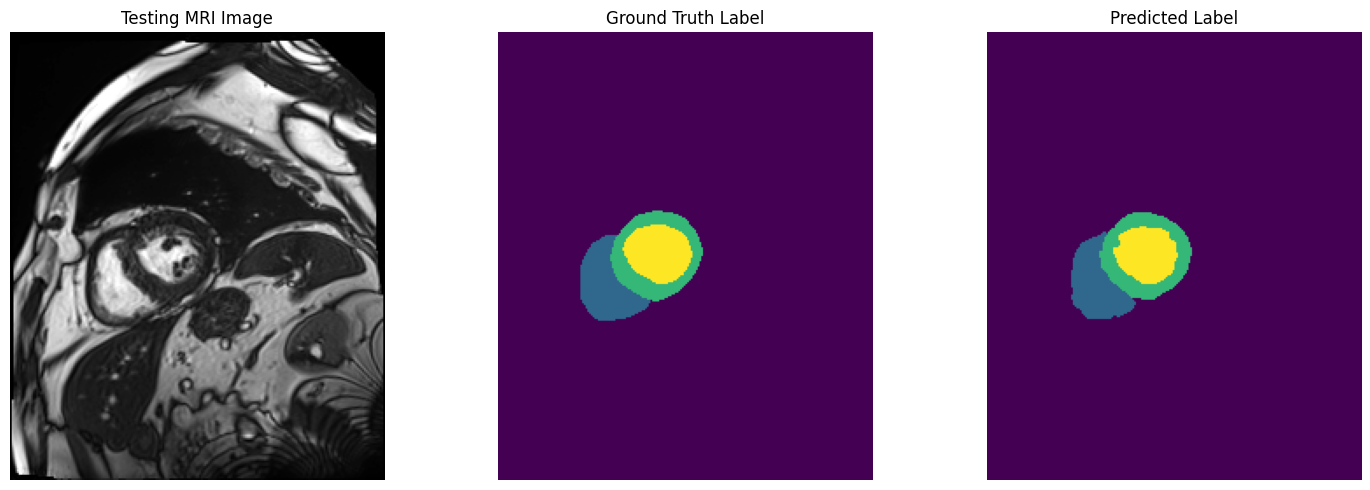

In [45]:
import matplotlib.pyplot as plt
import torch
import numpy as np

first_model.eval()

# Select a test frame and slice
frame_idx = 20
slice_idx = 2

image = torch.as_tensor(
    test_frames[frame_idx][slice_idx],
    dtype=torch.float32
)

label = torch.as_tensor(
    test_labels[frame_idx][slice_idx],
    dtype=torch.long
)

# Prepare input for model: [B, C, H, W]
input_image = image.unsqueeze(0).unsqueeze(0).to(device)

with torch.inference_mode():
    output = first_model(input_image)
    prediction = output.argmax(dim=1).squeeze(0).cpu()

# Plot
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Testing MRI Image")

axes[1].imshow(label, cmap="viridis", vmin=0, vmax=3)
axes[1].set_title("Ground Truth Label")

axes[2].imshow(prediction, cmap="viridis", vmin=0, vmax=3)
axes[2].set_title("Predicted Label")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()